# IND320 project work – Part 3

This notebook samples NVE electricity regions, downloads ERA5 hourly weather from Open-Meteo, detects precipitation outliers with DCT/SPC and temperature anomalies with LOF, and analyses reservoir filling with STL and a spectrogram.

**Public links:** [GitHub repository](https://github.com/M03ZGH/ind320-app) · [Streamlit app](https://ind320-data-to-decision-moez.streamlit.app/)

In [10]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'src' / 'ind320_app').exists():
    raise RuntimeError('Run this notebook from the ind320-app folder.')
sys.path.insert(0, str(PROJECT_ROOT / 'src'))

from ind320_app.data import load_reservoir_data
from ind320_app.part3 import (
    download_weather, plot_lof_temperature, plot_spc_precipitation,
    plot_spectrogram, plot_stl, sample_region_coordinates,
)

SHAPEFILE = PROJECT_ROOT / 'data' / 'NVE_Region.shp'


## 1. Sample 1000 locations per NVE region

The source polygons may use different names for combined areas. The shared function preserves the names from the downloaded shapefile and transforms coordinates to WGS84 before returning longitude/latitude pairs. NO3 is the precipitation-region label used for the NVE region mapping in the weather request.

In [11]:
if not SHAPEFILE.exists():
    raise FileNotFoundError('Download NVE_Region.shp, .shx, .dbf and .prj into data/.')
coordinates = sample_region_coordinates(SHAPEFILE, points_per_region=1000, random_state=42)
print({region: len(points) for region, points in coordinates.items()})


{'RV': 1000, 'RM': 1000, 'RN': 1000, 'RÃ\x98': 1000, 'RS': 1000}


In [12]:
# Brukes til praktisk API-testing
coordinates_test = {
    region: points[:10]
    for region, points in coordinates.items()
}

## 2. ERA5 weather data for NO3 in 2024

Open-Meteo supports batched coordinates. The function sends 10 sampled locations per request, caches completed batches and averages the hourly precipitation, temperature and wind speed across all 1000 sampled locations. The mapping from the sampled NVE electricity regions to NO3 is made by the shared region alias used by the download function.

In [13]:
import importlib
import ind320_app.part3 as part3

importlib.reload(part3)
download_weather = part3.download_weather

In [14]:
weather_no3 = download_weather(
    'NO3', '2024-01-01', '2024-12-31', coordinates,
    batch_size=10,
    request_pause=2.0,
    cache_dir=PROJECT_ROOT / 'data' / 'weather_cache',
    show_progress=True,
)
display(weather_no3.head())
print('Hourly observations:', len(weather_no3))


Weather download: batch 1/100 (  1.0%) | points 10/1000 | cache
Weather download: batch 2/100 (  2.0%) | points 20/1000 | cache
Weather download: batch 3/100 (  3.0%) | points 30/1000 | cache
Weather download: batch 4/100 (  4.0%) | points 40/1000 | cache
Weather download: batch 5/100 (  5.0%) | points 50/1000 | cache
Weather download: batch 6/100 (  6.0%) | points 60/1000 | cache
Weather download: batch 7/100 (  7.0%) | points 70/1000 | cache
Weather download: batch 8/100 (  8.0%) | points 80/1000 | cache
Weather download: batch 9/100 (  9.0%) | points 90/1000 | cache
Weather download: batch 10/100 ( 10.0%) | points 100/1000 | cache
Weather download: batch 11/100 ( 11.0%) | points 110/1000 | cache
Weather download: batch 12/100 ( 12.0%) | points 120/1000 | cache
Weather download: batch 13/100 ( 13.0%) | points 130/1000 | cache
Weather download: batch 14/100 ( 14.0%) | points 140/1000 | cache
Weather download: batch 15/100 ( 15.0%) | points 150/1000 | cache
Weather download: batch 16/1

,precipitation,temperature_2m,wind_speed_10m
time,,,
2024-01-01 00:00:00+00:00,0.0014,-7.5063,27.1967
2024-01-01 01:00:00+00:00,0.0021,-7.5743,27.1660
2024-01-01 02:00:00+00:00,0.0021,-7.4283,27.3894
2024-01-01 03:00:00+00:00,0.0021,-7.3288,27.5036
2024-01-01 04:00:00+00:00,0.0006,-7.2007,27.6741


Hourly observations: 8784


In [ ]:
# 2.1 Publish prepared weather data to MongoDB for the public Streamlit app.
import tomllib
from ind320_app.part3 import publish_weather_to_mongodb

secrets_path = PROJECT_ROOT / '.streamlit' / 'secrets.toml'
if not secrets_path.exists():
    raise FileNotFoundError('Create .streamlit/secrets.toml with [mongo].uri before publishing.')
with secrets_path.open('rb') as file:
    mongo_secrets = tomllib.load(file)
mongo_uri = mongo_secrets.get('mongo', {}).get('uri', '')
written = publish_weather_to_mongodb(
    weather_no3,
    region='NO3',
    mongo_uri=mongo_uri,
    collection='weather',
)
print(f'MongoDB weather upserts completed: {written:,}')


## 3. Precipitation: DCT high-pass filter and robust SPC

The seasonal component is reconstructed from the first DCT coefficients. With cutoff=12, only the 12 slowest components are retained for the seasonal estimate; the remaining variation is tested. Robust median/MAD limits are calculated from the seasonally adjusted values, while the plot deliberately shows only the original precipitation, limits and highlighted outliers.

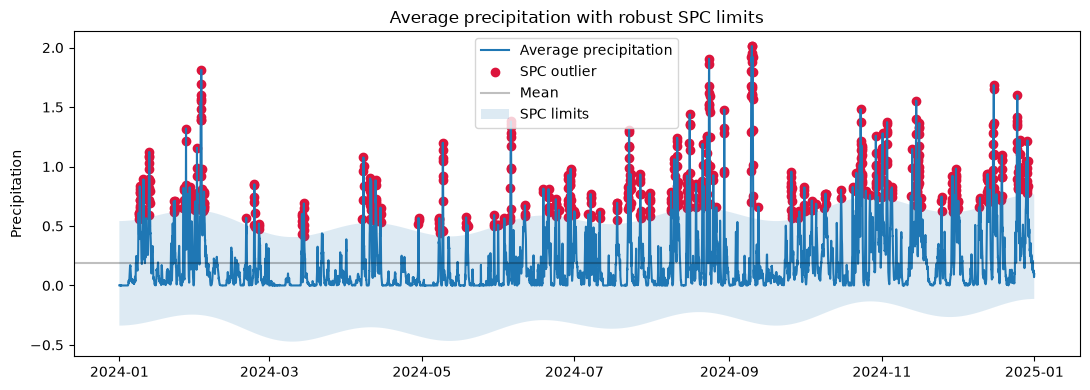

SPC outliers: 651


In [20]:
precipitation_figure, precipitation_summary = plot_spc_precipitation(
    weather_no3['precipitation'], cutoff=12, sigma=3.0
)
plt.show(precipitation_figure)
print('SPC outliers:', int(precipitation_summary['outlier'].sum()))


## 4. Temperature: Local Outlier Factor


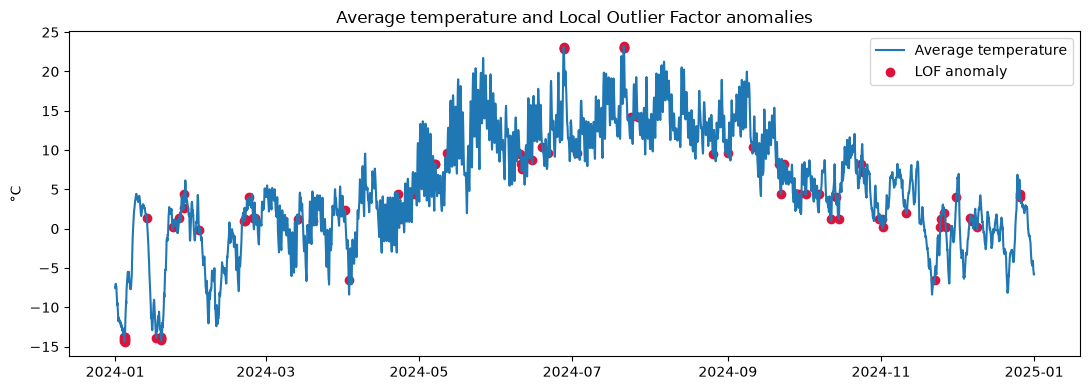

LOF anomalies: 88


In [21]:
temperature_figure, temperature_summary = plot_lof_temperature(
    weather_no3['temperature_2m'], contamination=0.01
)
plt.show(temperature_figure)
print('LOF anomalies:', int(temperature_summary['anomaly'].sum()))


## 5. STL decomposition of reservoir degree of filling

The series below is the whole-Norway filling series (NVE area type NO, area number 0). It is named `national_filling` to distinguish it from the NO3 weather region.

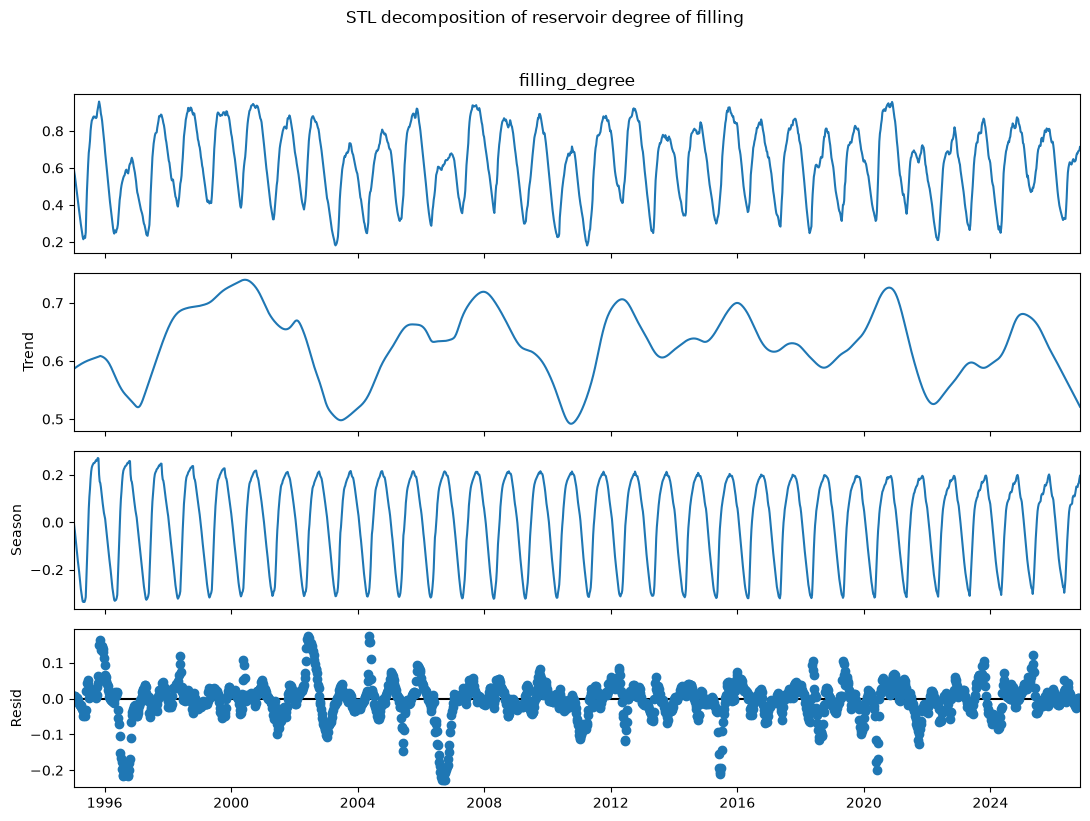

In [22]:
reservoirs = load_reservoir_data()
national_filling = (
    reservoirs[(reservoirs['area_type'] == 'NO') & (reservoirs['area_number'] == 0)]
    .set_index('date')['filling_degree'].dropna()
)
stl_figure = plot_stl(national_filling, seasonal=13, trend=None, robust=True)
plt.show(stl_figure)


## 6. Spectrogram

The spectrogram shows how the frequency content of reservoir filling changes over time. The series is linearly detrended before calculating power, and the colour scale is logarithmic (dB) so weaker components remain visible. Bright areas indicate stronger periodic components. Because the observations are weekly, the frequency is measured in cycles per week and dates are shown on the x-axis.


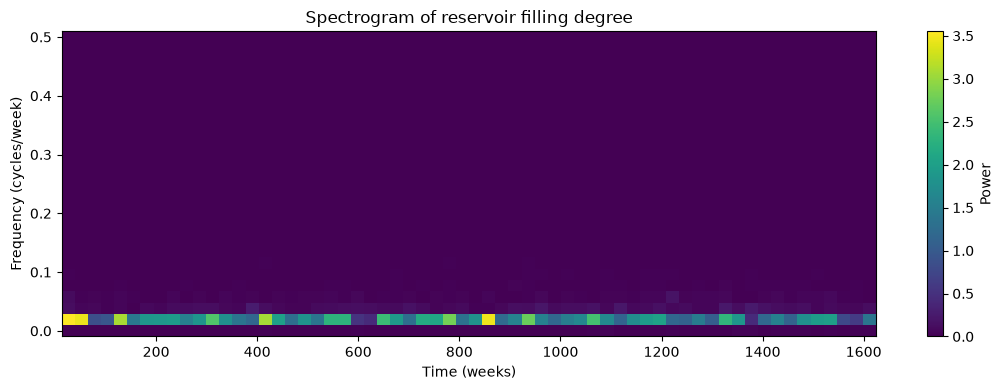

In [23]:
spectrogram_figure = plot_spectrogram(national_filling, window_length=52, overlap=0.5)
plt.show(spectrogram_figure)


## 7. Log (300–500 words)

In Part 3 I extended the Part 2 API pipeline with spatial weather data and time-series methods. I downloaded the NVE electricity-area polygons from Atlas and sampled 1000 reproducible locations per region. The sampled geometries were transformed to WGS84 so that their longitude and latitude could be sent to Open-Meteo. The weather function accepts a region and interval, requests hourly ERA5 reanalysis data, and averages precipitation, temperature and wind speed across the sampled points. Open-Meteo coordinates are batched to avoid making one HTTP request per point.

The weather label NO3 is mapped to the sampled NVE region aliases in the shared download function; it is not the reservoir area type NO. For precipitation, I used a Discrete Cosine Transform to remove low-frequency seasonal variation. With a cutoff of 12, the first 12 DCT coefficients reconstruct the slow seasonal baseline. Robust median and median absolute deviation estimates from the seasonally adjusted values define statistical process-control limits. The chart keeps the original precipitation values and colours the observations outside those limits, while the seasonally adjusted series is used only for classification. For temperature, Local Outlier Factor identifies the requested 1% of observations as local anomalies. Both analyses return a plot and a table so the result is useful in the notebook and in the Streamlit app.

I also applied STL decomposition to the whole-Norway NVE degree-of-filling series (area type NO, number 0). The seasonal smoother, trend smoother and robust option are explicit parameters. A spectrogram provides a complementary view of periodic behaviour, with configurable window length and overlap. Before calculating the spectrogram I detrend the weekly series, show power in decibels, restrict the frequency axis to the useful range and label the time axis with dates. These choices make weaker periodic components and seasonal peaks easier to compare. Under each analysis, the notebook and app explain what the plot indicates rather than presenting an unexplained figure.

The Streamlit experience has two assignment-focused analysis pages. The time-series page groups STL and spectrogram in tabs, while the weather page groups SPC and LOF in tabs. Both pages expose relevant parameters and display errors explicitly. The notebook uses the same direct download function as the data-preparation step, then publishes the aggregated 2024 weather observations to MongoDB. The public weather page reads this prepared collection, which keeps the visitor experience fast and avoids repeating 1000-point API downloads. The test/development page was removed from the public navigation. The repository README documents the run order, MongoDB publication step and cache behaviour.

## 8. AI usage

AI tools were used as learning support to explain GeoPandas sampling, ERA5/Open-Meteo parameters, DCT filtering, robust statistics, LOF, STL and spectrograms. I reviewed the suggestions against the course requirements, adapted the implementation to the existing Part 2 repository, and tested the analysis functions with synthetic series and Python compilation. AI was also used to improve documentation and Streamlit layout. I kept responsibility for selecting the data, checking the numerical results, interpreting the figures and deciding which suggestions were appropriate. Secrets and credentials were not placed in the repository.